In [23]:
import pandas as pd
import seaborn as sns
import  matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import cohen_kappa_score, make_scorer
import optuna
import joblib
import shap
from scipy import stats 
from statsmodels.stats import multitest

In [2]:
df = pd.read_csv(r'C:\Users\gupta\Learn\Internship_DecodeLabs\Data\Diamond\Dataset\diamonds.csv')


# Data exploration

In [3]:
df.shape

(53940, 10)

In [4]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,b'Ideal',b'E',b'SI2',61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,b'Premium',b'E',b'SI1',59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,b'Good',b'E',b'VS1',56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,b'Premium',b'I',b'VS2',62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,b'Good',b'J',b'SI2',63.3,58.0,335.0,4.34,4.35,2.75


In [5]:
df[['cut','color','clarity']]

,cut,color,clarity
0,b'Ideal',b'E',b'SI2'
1,b'Premium',b'E',b'SI1'
2,b'Good',b'E',b'VS1'
3,b'Premium',b'I',b'VS2'
4,b'Good',b'J',b'SI2'
...,...,...,...
53935,b'Ideal',b'D',b'SI1'
53936,b'Good',b'D',b'SI1'
53937,b'Very Good',b'D',b'SI1'
53938,b'Premium',b'H',b'SI2'


In [6]:
cat_cols = ['cut','color','clarity']
for col in cat_cols:
    df[col] = df[col].str.split("'").str[1].astype(str)


In [7]:
df.dtypes

carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price      float64
'x'        float64
'y'        float64
'z'        float64
dtype: object

In [8]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
'x'        0
'y'        0
'z'        0
dtype: int64

In [9]:
cols = ["carat", "cut", "color", "clarity", "price"]
df.duplicated().sum()

np.int64(146)

In [10]:
df[df.duplicated(keep=False)]

,carat,cut,color,clarity,depth,table,price,'x','y','z'
1004,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1005,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
...,...,...,...,...,...,...,...,...,...,...
49557,0.71,Good,F,SI2,64.1,60.0,2130.0,0.00,0.00,0.00
50078,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17
52860,0.50,Fair,E,VS2,79.0,73.0,2579.0,5.21,5.18,4.09


In [11]:
df = df.drop_duplicates()

In [12]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,53794.00000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000
mean,0.79778,61.748080,57.458109,3933.065082,5.731214,5.734653,3.538714
std,0.47339,1.429909,2.233679,3988.114460,1.120695,1.141209,0.705037
min,0.20000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.40000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.70000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.04000,62.500000,59.000000,5326.750000,6.540000,6.540000,4.030000
max,5.01000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [13]:
df.shape

(53794, 10)

In [14]:
num_cols = [item for item in list(df.columns) if item not in cat_cols]
num_cols

['carat', 'depth', 'table', 'price', "'x'", "'y'", "'z'"]

In [15]:
cut_ranking = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
y_encoder = OrdinalEncoder(categories=[cut_ranking])
df['cut'] = y_encoder.fit_transform(df[['cut']])

# Statistical Analysis

In [22]:
cat_cols_wo_y = cat_cols.copy()
cat_cols_wo_y.remove('cut')
row = []
for c in cat_cols_wo_y:
    cont_t = pd.crosstab(df[c], df['cut'])
    ch2, p, dof, _ = stats.chi2_contingency(cont_t)
    v = stats.contingency.association(cont_t)
    row.append(
        {
            "feature": c,
            "p":p,
            'effect':v,
        }
    )

for c in num_cols:
    grps = [df.loc[df['cut']==i,c] for i in range(5)]
    f_stat, p  = stats.f_oneway(*grps,equal_var=False)
    n = len(df[c])
    k = len(grps)
    df_within = n - k 
    df_between = k - 1
    eta_sq = (f_stat * df_between) / (f_stat * df_between + df_within)
    row.append(
        {
            "feature": c,
            "p":p,
            'effect':eta_sq
        }
    )

In [26]:
result = pd.DataFrame(row)
reject,p_adj,_,_ = multitest.multipletests(result['p'], method="holm")
result['p_adj'] = p_adj
result['rejetc_null'] = reject
result

,feature,p,effect,p_adj,rejetc_null
0,color,5.822229e-51,0.037787,5.822229e-51,True
1,clarity,0.000000e+00,0.142483,0.000000e+00,True
2,carat,0.000000e+00,0.033691,0.000000e+00,True
3,depth,0.000000e+00,0.053689,0.000000e+00,True
4,table,0.000000e+00,0.420227,0.000000e+00,True
5,price,3.404718e-135,0.011985,6.809436e-135,True
6,'x',0.000000e+00,0.035919,0.000000e+00,True
7,'y',0.000000e+00,0.029478,0.000000e+00,True
8,'z',0.000000e+00,0.037148,0.000000e+00,True


**Findings**
- `table` has by far the strongest relationship with cut (eta-squared 0.42, large). `depth`
  is small to medium (0.05), and `clarity` is small to medium (Cramér's V 0.14).
- Size and price features (`carat`, `price`, `x`, `y`, `z`) and `color` have small effects
  (eta-squared / V below 0.05), despite p < 1e-300, because n is about 54,000.
- Cut depends mostly on proportions, which supports adding ratio features (x/y, z/x).
- Effect sizes of different types (V vs eta-squared) are not compared with each other.

# DATA ANALYSIS

## Distribution

In [ ]:
cat_cols

In [ ]:
fig, axes = plt.subplots(5,2,figsize=(16,16))
fig.suptitle('Data distribution')

for ax,col in zip(axes.flatten(),cat_cols+num_cols):
    if col in num_cols:        
        if col not in ["'x'","'y'","'z'"]:
            sns.kdeplot(df, x=col, hue='cut', log_scale=True, ax=ax, common_norm=False)
        else:
            sns.histplot(df, x=col, hue='cut', ax=ax, common_norm=False, multiple="stack")
    else:
        sns.countplot(df,x=col, hue='cut', ax=ax)

plt.tight_layout()

## Outliers

In [ ]:
num_cols

In [ ]:
fig, axes = plt.subplots(2,4,figsize=(16,10))
for ax,c in zip(axes.flatten(),num_cols):
    sns.boxplot(df[c],ax=ax)

## Price per categories

In [ ]:
cat_cols

In [ ]:
temp = num_cols.copy()
temp.remove('price')

In [ ]:
discrete_df = df[temp].apply(lambda x: pd.qcut(x,5))
discrete_df[['cut','price','clarity','color']]= df[['cut','price','clarity','color']]
discrete_df

In [ ]:
df[num_cols+['cut']].groupby(['cut']).agg(["median"])

In [ ]:
for col in list(discrete_df.columns):
    if col == 'price':
        continue
    sns.catplot(
    discrete_df.sample(frac=0.1,random_state=42), kind="bar",
    x=col, y="price", col="cut",
    height=4, aspect=1,
    errorbar=None, hue='cut'
            ).set_xticklabels(rotation=45)
       
plt.tight_layout()

### normalising based on carat

In [ ]:
temp_df = discrete_df.copy()
temp_df['price per carat'] = df['price']/df['carat']

In [ ]:
temp_df

In [ ]:
for col in list(discrete_df.columns):
    if col == 'price':
        continue
    sns.catplot(
    temp_df.sample(frac=0.1,random_state=42), kind="bar",
    x=col, y="price per carat", col="cut",
    height=4, aspect=1,
    errorbar=None, hue='cut'
            ).set_xticklabels(rotation=45)
       
plt.tight_layout()

# FInal analysis
<h3>After analysis, we can confirm that therre are bad values (0), mistakes in x,y,z cols similarly price col should be resolved to price per carat </h3>

In [16]:
df[(df["'x'"]==0 )| (df["'y'"]==0) | (df["'z'"]==0)].index

Index([ 2207,  2314,  4791,  5471, 10167, 11182, 11963, 13601, 15951, 24394,
       24520, 26123, 26243, 27112, 27429, 27503, 27739, 49556, 51506],
      dtype='int64')

In [17]:
df["'x'"] = df["'x'"].replace(0,df["'x'"].median())
df["'y'"] = df["'y'"].replace(0,df["'y'"].median())
df["'z'"] = df["'z'"].replace(0,df["'z'"].median())

# Corelation Plot

In [18]:
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

In [19]:
ord_enc = OrdinalEncoder(categories=[color_order,clarity_order])
cols_to_enc = [c for c in cat_cols if c != "cut"]
df[cols_to_enc] = ord_enc.fit_transform(df[cols_to_enc])


In [20]:
cat_cols = cols_to_enc
cat_cols

['color', 'clarity']

In [21]:
num_cols

['carat', 'depth', 'table', 'price', "'x'", "'y'", "'z'"]

In [22]:
def correlated_cols(df):
    cols = list(df.columns)
    cols.remove('cut')
    corr = df[cols].corr().abs()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    masked_corr = corr.mask(mask)
    
    axis_corr = sns.heatmap(
        masked_corr,
        vmin=0, vmax=1,
        cmap='coolwarm',
        square=True,
        annot=True,
        fmt='.2f',
        linewidths=0.5
    )

    threshold = 0.8
    pairs = (masked_corr.stack().loc[lambda s: s > threshold].sort_values(ascending=False))
    target_corr = df[cols].corrwith(df['cut']).abs()
    to_drop = set()
    print(target_corr)
    for (a,b),r in pairs.items():
        if a in to_drop or b in to_drop:
            continue
        weaker = a if target_corr[a] < target_corr[b] else b
        to_drop.add(weaker)
    return to_drop

carat      0.133376
color      0.020162
clarity    0.188327
depth      0.217078
table      0.433700
price      0.052241
'x'        0.124798
'y'        0.120772
'z'        0.149037
dtype: float64


{"'x'", "'y'", 'carat', 'price'}

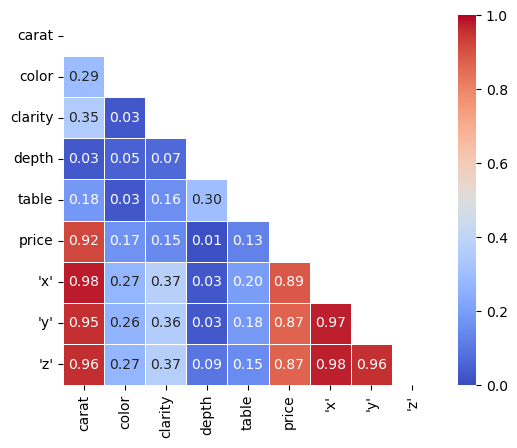

In [23]:
correlated_cols(df)

## Feature engineering

In [24]:
df

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,4.0,5.0,1.0,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,3.0,5.0,2.0,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,1.0,5.0,4.0,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,3.0,1.0,3.0,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,1.0,0.0,1.0,63.3,58.0,335.0,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4.0,6.0,2.0,60.8,57.0,2757.0,5.75,5.76,3.50
53936,0.72,1.0,6.0,2.0,63.1,55.0,2757.0,5.69,5.75,3.61
53937,0.70,2.0,6.0,2.0,62.8,60.0,2757.0,5.66,5.68,3.56
53938,0.86,3.0,2.0,1.0,61.0,58.0,2757.0,6.15,6.12,3.74


In [25]:
temp_df = df.copy()

In [26]:
temp_df['price_per_carat'] = df['price'] / df['carat']

In [27]:
temp_df['x/y'] = df["'x'"]/df["'y'"] 
temp_df['z/x'] = df["'z'"]/df["'x'"]
temp_df['volume_per_carat'] = df['carat']/(df["'x'"] * df["'y'"] * df["'z'"])

In [28]:
eng_feats = ['price_per_carat',"x/y","z/x","volume_per_carat"]

In [29]:
temp_df

,carat,cut,color,clarity,depth,table,price,'x','y','z',price_per_carat,x/y,z/x,volume_per_carat
0,0.23,4.0,5.0,1.0,61.5,55.0,326.0,3.95,3.98,2.43,1417.391304,0.992462,0.615190,0.006021
1,0.21,3.0,5.0,2.0,59.8,61.0,326.0,3.89,3.84,2.31,1552.380952,1.013021,0.593830,0.006086
2,0.23,1.0,5.0,4.0,56.9,65.0,327.0,4.05,4.07,2.31,1421.739130,0.995086,0.570370,0.006040
3,0.29,3.0,1.0,3.0,62.4,58.0,334.0,4.20,4.23,2.63,1151.724138,0.992908,0.626190,0.006207
4,0.31,1.0,0.0,1.0,63.3,58.0,335.0,4.34,4.35,2.75,1080.645161,0.997701,0.633641,0.005971
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4.0,6.0,2.0,60.8,57.0,2757.0,5.75,5.76,3.50,3829.166667,0.998264,0.608696,0.006211
53936,0.72,1.0,6.0,2.0,63.1,55.0,2757.0,5.69,5.75,3.61,3829.166667,0.989565,0.634446,0.006096
53937,0.70,2.0,6.0,2.0,62.8,60.0,2757.0,5.66,5.68,3.56,3938.571429,0.996479,0.628975,0.006116
53938,0.86,3.0,2.0,1.0,61.0,58.0,2757.0,6.15,6.12,3.74,3205.813953,1.004902,0.608130,0.006109


carat               0.133376
color               0.020162
clarity             0.188327
depth               0.217078
table               0.433700
price_per_carat     0.006004
x/y                 0.024303
z/x                 0.110019
volume_per_carat    0.252229
dtype: float64


set()

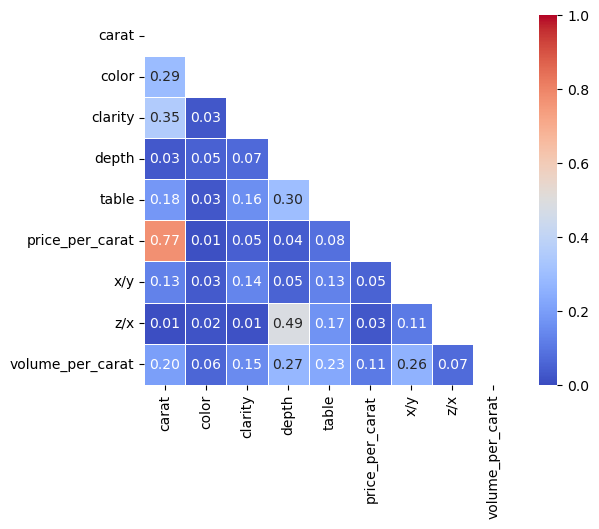

In [30]:
correlated_cols(temp_df.drop(columns=["price","'x'","'y'","'z'"]))

In [31]:
features_to_drop = ["price","'x'","'y'","'z'"]
df = temp_df

In [32]:
df = df.drop(columns=features_to_drop)

In [33]:
df[cols_to_enc] = ord_enc.inverse_transform(df[cols_to_enc])

In [34]:
df

,carat,cut,color,clarity,depth,table,price_per_carat,x/y,z/x,volume_per_carat
0,0.23,4.0,E,SI2,61.5,55.0,1417.391304,0.992462,0.615190,0.006021
1,0.21,3.0,E,SI1,59.8,61.0,1552.380952,1.013021,0.593830,0.006086
2,0.23,1.0,E,VS1,56.9,65.0,1421.739130,0.995086,0.570370,0.006040
3,0.29,3.0,I,VS2,62.4,58.0,1151.724138,0.992908,0.626190,0.006207
4,0.31,1.0,J,SI2,63.3,58.0,1080.645161,0.997701,0.633641,0.005971
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4.0,D,SI1,60.8,57.0,3829.166667,0.998264,0.608696,0.006211
53936,0.72,1.0,D,SI1,63.1,55.0,3829.166667,0.989565,0.634446,0.006096
53937,0.70,2.0,D,SI1,62.8,60.0,3938.571429,0.996479,0.628975,0.006116
53938,0.86,3.0,H,SI2,61.0,58.0,3205.813953,1.004902,0.608130,0.006109


In [35]:
temp = num_cols.copy()
num_cols = [col for col in temp if col not in features_to_drop]
num_cols.extend(eng_feats)

In [36]:
num_cols

['carat',
 'depth',
 'table',
 'price_per_carat',
 'x/y',
 'z/x',
 'volume_per_carat']

# Training

In [37]:
df.isna().sum()
df = df.dropna()

In [38]:
X_all = df.drop(columns=['cut'])
y_all = df['cut']

## Separating Validation set

In [39]:
X_train, X_val, y_train, y_val = train_test_split(
X_all, y_all, test_size=0.1, random_state=42, stratify=y_all)

In [40]:
X = X_train
y = y_train

## Pipeline

In [41]:
class IQRClipping(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.bounds_ = {}
        
    def fit(self, X, y=None):
        for col in X.columns:
            f_quart, t_quart = np.percentile(X[col],[25,75])
            iqr = t_quart - f_quart
            ub = t_quart + 1.5 * iqr
            lb = f_quart - 1.5 * iqr
            self.bounds_[col] = [lb,ub]
        return self

    def transform(self, X):
        X_temp = X.copy()
        for col in X.columns:
            if col in self.bounds_:
                lb,ub = self.bounds_[col]
                X_temp[col] = np.clip(X_temp[col],lb,ub)
        return X_temp
            
            

In [42]:
class IQRMasking(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.bounds_ = {}
        
    def fit(self, X, y=None):
        for col in X.columns:
            f_quart, t_quart = np.percentile(X[col],[25,75])
            iqr = t_quart - f_quart
            ub = t_quart + 1.5 * iqr
            lb = f_quart - 1.5 * iqr
            self.bounds_[col] = [lb,ub]
        return self

    def transform(self, X):
        X_temp = X.copy()
        mask_dict = {}
        for col in X.columns:
            if col in self.bounds_:
                lb,ub = self.bounds_[col]
                mask_dict[col] = (X_temp[col] < lb) | (X_temp[col] > ub)
        X_temp['is_outlier'] = pd.DataFrame(mask_dict).any(axis=1)
        return X_temp
            
            

In [43]:
def train_pipe(model,scalar=StandardScaler,remove_outlier=False, cat_encoder=OneHotEncoder):
    if scalar == None:
        scalar = ('scalar',"passthrough")
    else:
        scalar = ('scalar',scalar())
    if not remove_outlier:
        num_pipe = Pipeline([scalar])
    else:
        remove_outlier = ('outlier',remove_outlier())
        num_pipe = Pipeline([remove_outlier,scalar])

    cat_pipe = Pipeline([('encoder', cat_encoder())])
    preprocessor = ColumnTransformer(
        [
            ('cat',cat_pipe, cat_cols),
            ('num',num_pipe, num_cols)
        ]
    )
    train_pipe = Pipeline(
        [
            ('prep',preprocessor),
            ('model', model)
        ]
    )
    return train_pipe

In [44]:
def training(train_pipe, scorer=None, return_train = True):
    cv_results = cross_validate(train_pipe, X, y, cv=5, return_train_score=return_train, scoring=scorer, return_estimator=True)
    return cv_results
       

### Hypertuner function with optuna

In [45]:
def hypertuner(train_pipe,n_trials=100):
    def objective(trial):
        params = {
        # default 6, centered
        'max_depth': trial.suggest_int('max_depth', 3, 9),

        # default 0.3 is high; search 0.03-0.3 (log), geometric center ~0.1
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),

        'n_estimators': trial.suggest_int('n_estimators', 100, 800),

        # defaults are 1.0 (the max), so only go down
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),

        # default 1 is the min; log scale because small values matter most
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 20, log=True),

        # default 0 is the min; most useful values are small
        'gamma': trial.suggest_float('gamma', 0, 3),

        # default 1, centered in log space (0.1 to 10)
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10, log=True),

        # default 0; log scale from near zero
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
                    }

        train_pipe['model'].set_params(**params)
    
        cv_results = training(train_pipe, scores, return_train=True)    
        # qks_results = f'{cv_results['test_qks'].mean():.4f}+-{cv_results['test_qks'].std():4f}'
        f1_results = f'{cv_results['test_f1'].mean():.4f}+-{cv_results['test_f1'].std():.4f}'
        print(f'Test_f1_score:{f1_results}')
        train_qks_results = f'{cv_results['train_qks'].mean():.4f}+-{cv_results['train_qks'].std():4f}'
        train_f1_results = f'{cv_results['train_f1'].mean():.4f}+-{cv_results['train_f1'].std():.4f}'
        print(f'Train_score:qks:{train_qks_results},f1:{train_f1_results}')
        return cv_results['test_qks'].mean()  # An objective value linked with the Trial object.
        
    study = optuna.create_study(direction='maximize')
    study.enqueue_trial({
        'max_depth': 6, 'learning_rate': 0.3, 'subsample': 1.0,
        'colsample_bytree': 1.0, 'min_child_weight': 1, 'gamma': 0.0,
        'reg_lambda': 1.0, 'reg_alpha': 1e-3, 'n_estimators': 100
    })
    study.optimize(objective, n_trials=100)
    return study.best_params
    

### Logistic regression

#### Without Outlier removal and StandardScaling

In [47]:
log_pipe = train_pipe(LogisticRegression(max_iter=1000),remove_outlier=IQRClipping)

In [48]:
cv_results = training(log_pipe)

In [603]:
cols = list(cv_results['estimator'][0]['prep']['cat']['hot_encoder'].get_feature_names_out())+num_cols

In [597]:
coeffs = pd.DataFrame(data=cv_results['estimator'][0]['model'].coef_,columns=cols).agg(['mean','std']).T


In [604]:
results = f'{cv_results['test_score'].mean()}+-{cv_results['test_score'].std()}'

In [605]:
results

'0.6565858167422624+-0.003878841139808985'

In [606]:
log_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

#### With RobustScaling

In [584]:
log_pipe = train_pipe(LogisticRegression(max_iter=1000),scalar=RobustScaler, remove_outlier=IQRClipping)
cv_results = training(log_pipe)
# coeffs = pd.DataFrame(data=cv_results['estimator'][0]['model'].coef_,columns=cols).agg(['mean','std']).T
results = f'{cv_results['test_score'].mean()}+-{cv_results['test_score'].std()}'

In [585]:
results

'0.6565238524763121+-0.0041615786186591334'

In [586]:
log_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

 With RobustScaling: <br>
         outlier_yes:'0.5637506987143656+-0.005894035667493394' <br>
         outlier_no :'0.5656512017887088+-0.007547874668063564' <br>
         outlier_masking:'0.5728060368921184+-0.008479986269205549'<br>

 With StandardScalar: <br>
         outlier_yes:'0.5637506987143656+-0.005639382469167062'<br>
         outlier_no :'0.5656512017887088+-0.007547874668063564'<br>
         outlier_masking:'0.5729737283398547+-0.008454339881746068'<br>
 <h1>After feat engineering</h1>
  With RobustScaling: <br>
         outlier_yes:'0.6326102690006246+-0.005547823678288646' <br>
         outlier_no :'0.6344551366395328+-0.006075182063124691' <br>
         outlier_masking:'0.6322190046002032+-0.006165135046262806'<br>

 With StandardScalar: <br>
         outlier_yes:'0.6326382253886592+-0.005566597773706401'<br>
         outlier_no :'0.6349303288128382+-0.006258048750385746'<br>
         outlier_masking:'0.6319674205514031+-0.006136063489507419'<br>

<h1>Standard scalar with iqrcliping and after feature engineering gives the best possible result</h1>

### XGBOOST

In [46]:
scores = {
       "qks":make_scorer(cohen_kappa_score, weights="quadratic"),
        "f1":"f1_macro"
}


In [47]:
xgb_pipe = train_pipe(XGBClassifier(objective='reg:squarederror'),remove_outlier=None,scalar=None, cat_encoder=OrdinalEncoder)
xgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [48]:
xgb_pipe.set_params(prep__cat__encoder__categories=[color_order,clarity_order])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [50]:
cv_results = training(xgb_pipe, scores)

In [51]:
qks_results = f'{cv_results['train_qks'].mean()}+-{cv_results['train_qks'].std()}'
f1_results = f'{cv_results['train_f1'].mean()}+-{cv_results['train_f1'].std()}'

In [52]:
qks_results, f1_results

('0.9015780693991277+-0.0008834469785853859',
 '0.9149711216870292+-0.0013685165394386862')

In [53]:
qks_results = f'{cv_results['test_qks'].mean()}+-{cv_results['test_qks'].std()}'
f1_results = f'{cv_results['test_f1'].mean()}+-{cv_results['test_f1'].std()}'

In [54]:
qks_results, f1_results

('0.8404004149850774+-0.0027381546043828138',
 '0.8153182854061564+-0.0031001735526217655')

 With RobustScaling: <br>
         outlier_yes:
                   qks:(('0.773371619352907+-0.003377901725632658',
                     f1:'0.7099962881545605+-0.007242960720480314')<br>
         outlier_no :
                     qks:('0.7616402455985225+-0.0038721052231248053',
                      f1: 0.6847708560567553+-0.00505363622364797')<br>
        outlier_masking:
                     ('0.7714331051422008+-0.005515660003738091',
                     '0.7080201840777585+-0.007844640348551273')<br>

 With StandardScalar: <br>
         outlier_yes:
                     qks:('0.773371619352907+-0.003377901725632658',
                     f1:'0.7099962881545605+-0.007242960720480314')<br>
         outlier_no :
                     qks:('0.7616402455985225+-0.0038721052231248053',
                      f1: '0.6847708560567553+-0.00505363622364797')<br>
        outlier_masking:
                    ('0.7714331051422008+-0.005515660003738091',
                     '0.7080201840777585+-0.007844640348551273')<br>
        
 with passthrough:<br>
         outlier_masking:('0.7714331051422008+-0.005515660003738091',
                         '0.7080201840777585+-0.007844640348551273')<br>
        corelated_actual_removal:('0.7740930115295547+-0.0033402554791682184',
                         '0.7108424888367135+-0.004851503223049982')<br>
            non_removal:('0.8114241014170991+-0.0038439930382876586',
                         '0.7730762376334989+-0.004653219524986112')<br>
            higher_threshold_removal:('0.7868047633133168+-0.0021052205592752755',
 '0.7347958893141581+-0.0039758198078788266')

<h1>After feat engineering</h1>
with passthrough:<br>
            outlier_yes:
                   ('0.8243660103535919+-0.006056830582662732',
 '0.7947967052179663+-0.0047151141899628305')<br>
            outlier_no :
                     ('0.8106010481969307+-0.005337358216599779',
                     '0.7687503801483752+-0.0023157571364859535')<br>
         outlier_masking:('0.8223325948720314+-0.0055213190224656615',
                         '0.7941436084710609+-0.004991955739328384')<br>

<h2>Without subset duplicate removal...</h2>
    with passthrough:<br>
            outlier_yes:
                   ('0.834830237657257+-0.0056804031462535185',
                     '0.8100570085096146+-0.0058775925527357374')<br>
    with ordinalencoder<br>
             outlier_yes:
                      ('0.835088528397246+-0.0039064891638675246',
                     '0.8116180762024197+-0.005574576822754579')<br>
    ordinal explicit cat<br>
   ('0.8361312644090063+-0.0034388956341976683',
     '0.8119292578997894+-0.005828146164536281')

#### HyperTUNING


In [ ]:
best_params = hypertuner(xgb_pipe)

In [55]:
best_params = {'max_depth': 9, 'learning_rate': 0.04735663029912433, 'n_estimators': 780, 'subsample': 0.9909743882072464, 'colsample_bytree': 0.7977569768193515, 'min_child_weight': 2.566661058656693, 'gamma': 0.4038656548634874, 'reg_lambda': 0.8431338870808679, 'reg_alpha': 0.8471297228339474}

In [56]:
xgb_pipe['model'].set_params(**best_params)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7977569768193515
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegre

In [57]:
y_pred_val = xgb_pipe.fit(X,y).predict(X_val)
cohen_kappa_score(y_pred_val,y_val)

0.754130974787629

In [58]:
xgb_pipe.fit(X_all,y_all)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [59]:
joblib.dump(xgb_pipe, "pipeline/model_pipeline.joblib")
joblib.dump(y_encoder, "pipeline/y_encoder.joblib")


['pipeline/y_encoder.joblib']

In [60]:
model = xgb_pipe['model']
preprocessor = xgb_pipe['prep']
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(preprocessor.transform(X_val))
shap_values[0]

array([[-0.12846184, -0.13338909,  0.07291766, -0.07295696,  0.43026415],
       [-0.02160117, -0.04399492, -0.00459247,  0.00676034,  0.04622224],
       [-0.27025872, -0.10167412,  0.02300509, -0.1657472 ,  0.29336432],
       [-1.5952977 , -1.2549192 , -0.54525363,  0.24876788,  0.15532173],
       [-0.45159227, -0.842882  , -0.30460432, -1.3897877 ,  0.8701727 ],
       [ 0.22702579,  0.10084506, -0.4094759 ,  0.23867671, -0.627743  ],
       [ 0.17887898, -1.0537585 , -1.9524275 ,  1.3356299 ,  0.0384732 ],
       [-0.6093642 , -0.8706204 , -0.2045676 , -0.12888145,  0.21754515],
       [-0.2411527 , -0.11422689,  0.17891711, -0.03296534,  0.05299715]],
      dtype=float32)

In [80]:
features = [col.split("__")[1] for col in list(xgb_pipe['prep'].get_feature_names_out())]
features

['color',
 'clarity',
 'carat',
 'depth',
 'table',
 'price_per_carat',
 'x/y',
 'z/x',
 'volume_per_carat']

In [81]:
xgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [82]:
X_val

,carat,color,clarity,depth,table,price_per_carat,x/y,z/x,volume_per_carat
40207,0.51,I,SI1,62.5,57.0,2200.000000,1.005917,0.623529,0.006202
10707,1.11,I,SI1,61.4,60.0,4368.468468,0.993985,0.615734,0.006204
25360,0.28,F,VVS1,62.9,57.0,2292.857143,0.990408,0.631961,0.006229
27197,2.33,I,VS2,62.0,57.0,7512.446352,1.008284,0.617371,0.006153
18849,1.54,I,SI2,64.6,56.0,5017.532468,1.005510,0.643836,0.006182
...,...,...,...,...,...,...,...,...,...
14331,1.16,D,SI1,62.0,56.0,5004.310345,0.995562,0.621100,0.006100
37332,0.43,E,VS2,62.1,56.0,2281.395349,0.991786,0.623188,0.006073
10861,1.14,G,SI2,62.4,60.0,4276.315789,0.989505,0.627273,0.006255
44695,0.65,G,SI1,61.9,58.0,2480.000000,1.005445,0.617329,0.006226


In [134]:
shap.initjs()
model = xgb_pipe['model']
preprocessor = xgb_pipe['prep']
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(preprocessor.transform(X_val[:1]))

In [149]:
shap_values[0,:,4]

array([ 0.43026415,  0.04622224,  0.29336432,  0.15532173,  0.8701727 ,
       -0.627743  ,  0.0384732 ,  0.21754515,  0.05299715], dtype=float32)

# Regression